# NHANES 03 - Entrenamiento, selección y calibración del modelo

Corresponde a las etapas de **Preparación de los datos** y **Modelado** del proceso CRISP-DM y al **objetivo específico 2**: comparar la capacidad discriminativa y la calibración de Random Forest, XGBoost y LightGBM con la regresión logística, empleando los mismos predictores, particiones y procedimiento de evaluación.

Aplica las secciones 6 a 8 de `docs/protocolo_nhanes.md` (etiqueta `protocolo-nhanes-v1.1`):

1. Cuatro algoritmos con los ocho predictores no invasivos y las mismas 5 particiones `StratifiedGroupKFold` (semilla 42), **agrupadas por conglomerado** y estratificadas por `hba1c_elevada`.
2. Hiperparámetros elegidos por AUC-ROC media en validación cruzada.
3. Regla prefijada de elección: el algoritmo de mayor AUC-ROC media; si su ventaja sobre la regresión logística es menor a 0.01, se elige la regresión logística.
4. Calibración con predicciones fuera de partición; recalibración sigmoide si la pendiente queda fuera de [0.9, 1.1].
5. Umbral: máxima especificidad con sensibilidad ≥ 0.70.
6. Sin corrección del desbalance de clases.

**Solo se usa el conjunto de desarrollo.** Al final los cuatro modelos se congelan en `models/nhanes/` para la evaluación única con el conjunto de prueba.

In [1]:
import hashlib
import json
import subprocess
import warnings
from datetime import date
from pathlib import Path

import joblib
import lightgbm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
import sklearn
import statsmodels.api as sm
import xgboost
from lightgbm import LGBMClassifier
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score, roc_curve
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from statsmodels.nonparametric.smoothers_lowess import lowess
from xgboost import XGBClassifier

import preparacion_nhanes as pn
from preparacion_nhanes import DESENLACE, PREDICTORES, cargar_desarrollo

warnings.filterwarnings('ignore', category=UserWarning)
pd.set_option('display.float_format', '{:.4f}'.format)

SEMILLA = 42
SALIDA = Path('../../resultados/nhanes/03_entrenamiento')
MODELOS = Path('../../models/nhanes')
SALIDA.mkdir(parents=True, exist_ok=True)
MODELOS.mkdir(parents=True, exist_ok=True)

d = cargar_desarrollo()
X, y, grupos = d[PREDICTORES], d[DESENLACE].astype(int), d['conglomerado']
folds = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
particiones = list(folds.split(X, y, grupos))  # las mismas 5 particiones para todos los algoritmos

print(f'Desarrollo: {len(d):,} participantes, {y.sum():,} con HbA1c >= 5.7 % ({100 * y.mean():.2f}%), {grupos.nunique()} conglomerados')
print(f'scikit-learn {sklearn.__version__} | xgboost {xgboost.__version__} | lightgbm {lightgbm.__version__}')

C:\Users\Renzo\AppData\Roaming\Python\Python314\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Desarrollo: 18,264 participantes, 4,899 con HbA1c >= 5.7 % (26.82%), 163 conglomerados
scikit-learn 1.9.1 | xgboost 3.4.1 | lightgbm 4.7.0


### Particiones de la validación cruzada

Ningún conglomerado aparece en el entrenamiento y la validación de una misma partición. La estratificación mantiene una proporción de casos similar entre particiones, dentro de lo que permite agrupar por conglomerado.

In [2]:
filas = []
for i, (ent, val) in enumerate(particiones, 1):
    assert set(grupos.iloc[ent]).isdisjoint(grupos.iloc[val])
    filas.append({'partición': i, 'validación_n': len(val), 'conglomerados_validación': grupos.iloc[val].nunique(),
                  'prevalencia_validación_%': 100 * y.iloc[val].mean()})
pd.DataFrame(filas)

,partición,validación_n,conglomerados_validación,prevalencia_validación_%
0,1,3581,31,27.1991
1,2,3740,33,26.9519
2,3,3642,33,26.6337
3,4,3714,34,26.6020
4,5,3587,32,26.7354


## Preprocesamiento y algoritmos

El preprocesamiento va dentro de cada `Pipeline`, de modo que en la validación cruzada se ajusta solo con los datos de entrenamiento de cada partición: imputación con la mediana (continuas) o la moda (binarias) y, solo para la regresión logística, escalado estándar. Las mallas de hiperparámetros son las de la sección 7 del protocolo.

In [3]:
CONTINUAS = {'edad', 'imc', 'cintura'}


def preprocesador(escalar):
    continuas = [p for p in PREDICTORES if p in CONTINUAS]
    binarias = [p for p in PREDICTORES if p not in CONTINUAS]
    pasos_cont = [('imputar', SimpleImputer(strategy='median'))] + ([('escalar', StandardScaler())] if escalar else [])
    pasos_bin = [('imputar', SimpleImputer(strategy='most_frequent'))] + ([('escalar', StandardScaler())] if escalar else [])
    return ColumnTransformer([
        ('continuas', Pipeline(pasos_cont), continuas),
        ('binarias', Pipeline(pasos_bin), binarias),
    ])


ALGORITMOS = {
    'Regresión logística': (
        lambda: LogisticRegression(max_iter=5000),
        True,
        {'modelo__C': [0.01, 0.1, 1, 10]},
    ),
    'Random Forest': (
        lambda: RandomForestClassifier(n_estimators=500, random_state=SEMILLA, n_jobs=-1),
        False,
        {'modelo__max_depth': [4, 6, 8, None], 'modelo__min_samples_leaf': [10, 30, 50]},
    ),
    'XGBoost': (
        lambda: XGBClassifier(subsample=0.8, random_state=SEMILLA, n_jobs=-1, eval_metric='logloss'),
        False,
        {'modelo__n_estimators': [200, 500], 'modelo__max_depth': [2, 3, 4], 'modelo__learning_rate': [0.03, 0.1]},
    ),
    'LightGBM': (
        lambda: LGBMClassifier(min_child_samples=30, random_state=SEMILLA, n_jobs=-1, verbose=-1),
        False,
        {'modelo__n_estimators': [200, 500], 'modelo__num_leaves': [7, 15, 31], 'modelo__learning_rate': [0.03, 0.1]},
    ),
}

## Validación cruzada

Para cada algoritmo se busca la mejor combinación de hiperparámetros y se obtienen las predicciones fuera de partición (*out-of-fold*), con las que se calculan AUC-ROC, AUC-PR y Brier score sin que ningún participante sea evaluado por un modelo que lo vio al entrenar.

In [4]:
def fuera_de_particion(modelo, X, y):
    p = np.empty(len(y))
    for ent, val in particiones:
        p[val] = clone(modelo).fit(X.iloc[ent], y.iloc[ent]).predict_proba(X.iloc[val])[:, 1]
    return p


busquedas, oof, filas = {}, {}, []
for nombre, (crear, escalar, malla) in ALGORITMOS.items():
    pipe = Pipeline([('prep', preprocesador(escalar)), ('modelo', crear())])
    gs = GridSearchCV(pipe, malla, scoring='roc_auc', cv=particiones, n_jobs=-1).fit(X, y)
    busquedas[nombre], oof[nombre] = gs, fuera_de_particion(gs.best_estimator_, X, y)
    i = gs.best_index_
    filas.append({
        'algoritmo': nombre,
        'AUC_ROC_media': gs.cv_results_['mean_test_score'][i],
        'AUC_ROC_de': gs.cv_results_['std_test_score'][i],
        'AUC_PR_oof': average_precision_score(y, oof[nombre]),
        'Brier_oof': brier_score_loss(y, oof[nombre]),
        'hiperparametros': {k.replace('modelo__', ''): v for k, v in gs.best_params_.items()},
    })

cv = pd.DataFrame(filas)
cv['Brier_nulo'] = brier_score_loss(y, np.full(len(y), y.mean()))
cv.to_csv(SALIDA / 'validacion_cruzada.csv', index=False)
cv

,algoritmo,AUC_ROC_media,AUC_ROC_de,AUC_PR_oof,Brier_oof,hiperparametros,Brier_nulo
0,Regresión logística,0.7546,0.0053,0.5025,0.1661,{'C': 1},0.1963
1,Random Forest,0.7504,0.0058,0.4924,0.1669,"{'max_depth': None, 'min_samples_leaf': 30}",0.1963
2,XGBoost,0.7523,0.0049,0.4970,0.1663,"{'learning_rate': 0.03, 'max_depth': 3, 'n_est...",0.1963
3,LightGBM,0.7519,0.0041,0.4954,0.1665,"{'learning_rate': 0.03, 'n_estimators': 200, '...",0.1963


In [5]:
# AUC-ROC de cada partición con los hiperparámetros elegidos
por_particion = pd.DataFrame({
    nombre: [gs.cv_results_[f'split{k}_test_score'][gs.best_index_] for k in range(5)]
    for nombre, gs in busquedas.items()
}, index=[f'partición {k + 1}' for k in range(5)])
por_particion.to_csv(SALIDA / 'auc_por_particion.csv')
por_particion

,Regresión logística,Random Forest,XGBoost,LightGBM
partición 1,0.7457,0.7435,0.7445,0.7459
partición 2,0.7572,0.7512,0.7530,0.7525
partición 3,0.7599,0.7589,0.7573,0.7570
partición 4,0.7515,0.7447,0.7492,0.7488
partición 5,0.7586,0.7539,0.7574,0.7554


## Elección del algoritmo (regla prefijada)

Se identifica el algoritmo con mayor AUC-ROC media. Si su ventaja sobre la regresión logística es menor a 0.01, se elige la regresión logística por parsimonia e interpretabilidad.

In [6]:
t = cv.set_index('algoritmo')['AUC_ROC_media']
mejor = t.idxmax()
ventaja = t[mejor] - t['Regresión logística']
seleccionado = 'Regresión logística' if ventaja < 0.01 else mejor
print(f'Mayor AUC = {mejor} ({t[mejor]:.4f}); ventaja sobre la regresión logística = {ventaja:+.4f} -> se elige: {seleccionado}')

Mayor AUC = Regresión logística (0.7546); ventaja sobre la regresión logística = +0.0000 -> se elige: Regresión logística


## Calibración (predicciones fuera de partición)

- **Pendiente:** regresión logística del desenlace sobre el logit de la probabilidad predicha.
- **Intercepto** (calibración global): estimado con el logit como *offset*.
- **Razón O/E:** proporción observada de casos dividida entre la probabilidad media predicha.
- **ICI:** diferencia absoluta media entre la probabilidad predicha y la observada suavizada (lowess).

Si la pendiente queda fuera de [0.9, 1.1], el modelo se recalibra con `CalibratedClassifierCV` (sigmoide). La recalibración también respeta los conglomerados: dentro de cada partición externa, la calibración usa particiones agrupadas internas, y el modelo final usa las 5 particiones del desarrollo.

Los criterios de 0.8–1.2 (pendiente) y 0.9–1.1 (O/E) de la sección 14 se aplican al conjunto de prueba. Aquí solo se reportan como referencia.

In [7]:
def calibracion(y_real, p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    lp = np.log(p / (1 - p))
    pendiente = sm.Logit(y_real, sm.add_constant(lp)).fit(disp=False).params.iloc[1]
    intercepto = sm.GLM(y_real, np.ones(len(lp)), offset=lp, family=sm.families.Binomial()).fit().params.iloc[0]
    suavizada = lowess(y_real, p, frac=2 / 3, it=0, return_sorted=False)
    return {'pendiente': pendiente, 'intercepto': intercepto, 'O/E': np.mean(y_real) / np.mean(p),
            'ICI': np.mean(np.abs(suavizada - p))}


def recalibrado_fuera_de_particion(base, X, y):
    p = np.empty(len(y))
    for ent, val in particiones:
        internas = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
                        .split(X.iloc[ent], y.iloc[ent], grupos.iloc[ent]))
        modelo = CalibratedClassifierCV(clone(base), method='sigmoid', cv=internas)
        p[val] = modelo.fit(X.iloc[ent], y.iloc[ent]).predict_proba(X.iloc[val])[:, 1]
    return p


finales, filas = {}, []
for nombre, gs in busquedas.items():
    inicial = calibracion(y, oof[nombre])
    recalibrar = not 0.9 <= inicial['pendiente'] <= 1.1
    modelo = gs.best_estimator_
    if recalibrar:
        oof[nombre] = recalibrado_fuera_de_particion(gs.best_estimator_, X, y)
        modelo = CalibratedClassifierCV(clone(gs.best_estimator_), method='sigmoid', cv=particiones)
    final = calibracion(y, oof[nombre])
    finales[nombre] = modelo
    filas.append({
        'algoritmo': nombre, 'pendiente_inicial': inicial['pendiente'], 'recalibrado': recalibrar,
        'pendiente_final': final['pendiente'], 'intercepto_final': final['intercepto'],
        'O/E_final': final['O/E'], 'ICI_final': final['ICI'],
        'AUC_ROC_oof_final': roc_auc_score(y, oof[nombre]),
        'Brier_oof_final': brier_score_loss(y, oof[nombre]),
    })

calib = pd.DataFrame(filas)
calib.to_csv(SALIDA / 'calibracion.csv', index=False)
calib

,algoritmo,pendiente_inicial,recalibrado,pendiente_final,intercepto_final,O/E_final,ICI_final,AUC_ROC_oof_final,Brier_oof_final
0,Regresión logística,0.9956,False,0.9956,-0.0009,0.9995,0.0137,0.7543,0.1661
1,Random Forest,1.0655,False,1.0655,0.0015,1.0010,0.0073,0.7501,0.1669
2,XGBoost,1.0043,False,1.0043,0.0002,1.0001,0.0019,0.7520,0.1663
3,LightGBM,1.0155,False,1.0155,0.0002,1.0001,0.0016,0.7516,0.1665


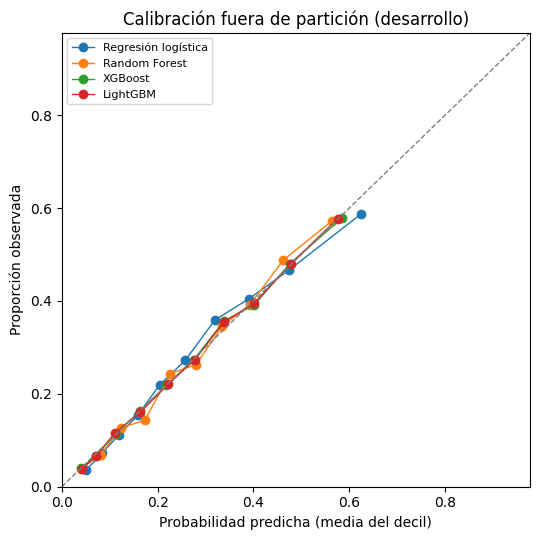

In [8]:
fig, ax = plt.subplots(figsize=(5.5, 5.5))
for nombre, p in oof.items():
    deciles = pd.qcut(p, 10, labels=False, duplicates='drop')
    g = pd.DataFrame({'p': p, 'y': y.to_numpy(), 'd': deciles}).groupby('d').mean()
    ax.plot(g['p'], g['y'], marker='o', label=nombre, lw=1)
ax.plot([0, 1], [0, 1], ls='--', color='grey', lw=1)
lim = max(max(p.max() for p in oof.values()), 0.8)
ax.set(xlim=(0, lim), ylim=(0, lim), xlabel='Probabilidad predicha (media del decil)', ylabel='Proporción observada',
       title='Calibración fuera de partición (desarrollo)')
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(SALIDA / 'calibracion_oof.png', dpi=150)
plt.show()

## Umbral de clasificación

Con las predicciones fuera de partición finales, el umbral que maximiza la especificidad manteniendo una sensibilidad ≥ 0.70. El umbral solo se usa para reportar sensibilidad y especificidad; el sistema web no muestra categorías de riesgo.

In [9]:
def umbral_sensibilidad(y_real, p, sensibilidad_min=0.70):
    fpr, tpr, umbrales = roc_curve(y_real, p)
    ok = tpr >= sensibilidad_min
    i = np.argmax(np.where(ok, 1 - fpr, -1))
    return umbrales[i], tpr[i], 1 - fpr[i]


umbrales, filas = {}, []
for nombre, p in oof.items():
    u, sens, esp = umbral_sensibilidad(y, p)
    umbrales[nombre] = float(u)
    filas.append({'algoritmo': nombre, 'umbral': u, 'sensibilidad_oof': sens, 'especificidad_oof': esp})
tabla_umbrales = pd.DataFrame(filas)
tabla_umbrales.to_csv(SALIDA / 'umbrales.csv', index=False)
tabla_umbrales

,algoritmo,umbral,sensibilidad_oof,especificidad_oof
0,Regresión logística,0.2766,0.7001,0.6842
1,Random Forest,0.2926,0.7001,0.6739
2,XGBoost,0.2918,0.7001,0.6800
3,LightGBM,0.2924,0.7003,0.6770


## Congelamiento de los modelos

Cada modelo final se reentrena con todo el desarrollo y se guarda en `models/nhanes/` junto con sus predictores, umbral, métricas de validación cruzada, versiones de las librerías, el commit de Git y el SHA-256 de los datos con que se entrenó. Se guardan los cuatro porque la evaluación final los compara (DeLong). A partir de aquí **ningún modelo, hiperparámetro ni umbral se modifica**.

In [10]:
try:
    commit = subprocess.run(['git', 'rev-parse', '--short', 'HEAD'], capture_output=True, text=True).stdout.strip()
except OSError:
    commit = None

SLUG = {'Regresión logística': 'regresion_logistica', 'Random Forest': 'random_forest', 'XGBoost': 'xgboost', 'LightGBM': 'lightgbm'}
registro = []
for nombre, modelo in finales.items():
    ajustado = modelo.fit(X, y)
    fila_cv = cv.set_index('algoritmo').loc[nombre]
    fila_cal = calib.set_index('algoritmo').loc[nombre]
    artefacto = {
        'modelo': ajustado,
        'algoritmo': nombre,
        'predictores': PREDICTORES,
        'umbral': umbrales[nombre],
        'seleccionado': nombre == seleccionado,
        'recalibrado': bool(fila_cal['recalibrado']),
        'hiperparametros': fila_cv['hiperparametros'],
        'auc_cv': float(fila_cv['AUC_ROC_media']),
        'prevalencia_desarrollo': float(y.mean()),
        'desenlace': 'HbA1c >= 5.7 % (NHANES LBXGH)',
        'datos_entrenamiento': 'NHANES 2007-2008 a 2017-marzo 2020, conjunto de desarrollo; 20-69 años sin diagnóstico previo de diabetes ni prediabetes',
        'sha256_desarrollo': pn.sha256(pn.RUTA_DESARROLLO),
        'sha256_particion': pn.sha256(pn.RUTA_PARTICION),
        'versiones': {'scikit-learn': sklearn.__version__, 'xgboost': xgboost.__version__, 'lightgbm': lightgbm.__version__},
        'fecha': date.today().isoformat(),
        'commit_git': commit,
    }
    ruta = MODELOS / f'{SLUG[nombre]}.joblib'
    joblib.dump(artefacto, ruta, compress=3)
    registro.append({'archivo': ruta.name, 'seleccionado': artefacto['seleccionado'], 'MB': ruta.stat().st_size / 1e6,
                     'sha256': pn.sha256(ruta)})

(MODELOS / 'seleccion.json').write_text(json.dumps(
    {'seleccionado': f'{SLUG[seleccionado]}.joblib', 'algoritmo': seleccionado}, ensure_ascii=False, indent=2), encoding='utf-8')
registro = pd.DataFrame(registro)
registro.to_csv(MODELOS / 'registro_modelos.csv', index=False)
registro

,archivo,seleccionado,MB,sha256
0,regresion_logistica.joblib,True,0.0023,fa1be5d6a0ab00640f41549cd27725aa975f555fd55e02...
1,random_forest.joblib,False,7.6600,cb8313814e6b276f347699b448c7904be173b8d41e6de0...
2,xgboost.joblib,False,0.0495,79c170f4c7e2972fd7cc3c899ed2347f1bcfafcc861529...
3,lightgbm.joblib,False,0.0646,2059531018f27a9467f6232e007ba25629f098c729431e...


## Interpretación del modelo seleccionado (SHAP)

Valores SHAP calculados sobre el desarrollo para el modelo que usará el sistema web. Muestran qué variables influyen más en la probabilidad estimada y en qué dirección. Se emplea una muestra de 1,000 participantes para la explicación y 200 como fondo. Son contribuciones a la estimación del modelo, **no efectos causales**.

Background dataset has 200 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=200 when initializing the masker.


ExactExplainer explainer:  23%|██▎       | 231/1000 [00:00<?, ?it/s]

ExactExplainer explainer:  23%|██▎       | 234/1000 [00:10<00:31, 24.13it/s]

ExactExplainer explainer:  24%|██▎       | 237/1000 [00:10<00:31, 23.87it/s]

ExactExplainer explainer:  24%|██▍       | 240/1000 [00:10<00:37, 20.13it/s]

ExactExplainer explainer:  24%|██▍       | 243/1000 [00:10<00:35, 21.39it/s]

... (248 outputs left out)

ExactExplainer explainer:  99%|█████████▉| 994/1000 [00:42<00:00, 23.42it/s]

ExactExplainer explainer: 100%|█████████▉| 997/1000 [00:42<00:00, 22.42it/s]

ExactExplainer explainer: 100%|██████████| 1000/1000 [00:42<00:00, 23.10it/s]

ExactExplainer explainer: 1001it [00:42, 18.17it/s]                          

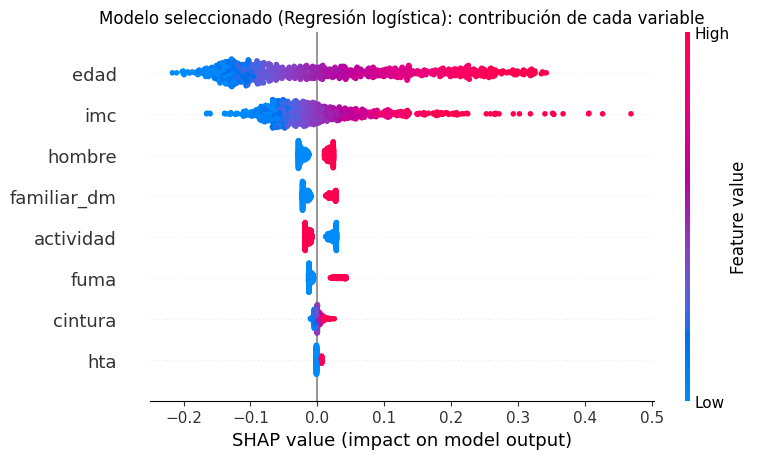

,variable,media_abs_SHAP
0,edad,0.1190
2,imc,0.0605
1,hombre,0.0208
5,familiar_dm,0.0193
6,actividad,0.0186
7,fuma,0.0160
3,cintura,0.0037
4,hta,0.0022


In [11]:
elegido = finales[seleccionado]
fondo = X.sample(200, random_state=SEMILLA)
muestra = X.sample(1000, random_state=SEMILLA + 1)

explicador = shap.Explainer(lambda Z: elegido.predict_proba(pd.DataFrame(Z, columns=PREDICTORES))[:, 1],
                            fondo, feature_names=PREDICTORES)
valores = explicador(muestra)

importancia = pd.DataFrame({
    'variable': PREDICTORES,
    'media_abs_SHAP': np.abs(valores.values).mean(axis=0),
}).sort_values('media_abs_SHAP', ascending=False)
importancia.to_csv(SALIDA / 'shap_importancia.csv', index=False)

shap.plots.beeswarm(valores, show=False, max_display=len(PREDICTORES))
plt.title(f'Modelo seleccionado ({seleccionado}): contribución de cada variable')
plt.tight_layout()
plt.savefig(SALIDA / 'shap_resumen.png', dpi=150)
plt.show()
importancia

## Interpretación

**Discriminación.** Los cuatro algoritmos obtienen un AUC-ROC medio muy parecido en la validación cruzada agrupada, entre 0.750 y 0.755, con diferencias menores a 0.005 que caen dentro de la variación entre particiones (DE ≈ 0.005). La regresión logística obtiene el mayor AUC (0.755), así que se elige por la regla prefijada sin necesidad de aplicar el criterio de parsimonia. Con estos ocho predictores, los métodos de ensamble no aportan discriminación adicional.

**Respecto de la meta.** La meta (AUC-ROC ≥ 0.75) se contrasta solo con el conjunto de prueba. El AUC de validación cruzada queda apenas por encima de ella, de modo que en la prueba el AUC puede quedar por encima o por debajo de 0.75. El modelo **no se ajustará** para acercarse a la meta: el resultado de la prueba se reportará tal cual.

**Calibración.** Ningún modelo necesitó recalibración: todas las pendientes están entre 0.99 y 1.07, la razón O/E está entre 0.9995 y 1.001, y el Brier (0.166) es menor que el del modelo nulo (0.196). La curva por deciles sigue la diagonal. Las probabilidades del modelo seleccionado van, en promedio por decil, de aproximadamente 5 % a 62 %. Con factores no invasivos, el modelo rara vez asigna probabilidades muy altas o muy bajas; esto es una característica de la información disponible, no un error de calibración.

**Umbral.** El umbral de 0.277 da una sensibilidad de 0.70 y una especificidad de 0.68 en el desarrollo. Se usa solo para reportar esas métricas.

**SHAP.** La edad y el IMC concentran la mayor parte de la contribución, seguidos del sexo, el antecedente familiar, la actividad física y el tabaquismo. El perímetro abdominal y la hipertensión aportan muy poco una vez que el modelo incluye las demás variables, lo que es coherente con los OR ajustados del notebook 02. Son contribuciones a la estimación, **no efectos causales**.

Los cuatro modelos quedaron congelados en `models/nhanes/` con el SHA-256 de los datos de desarrollo y de la partición. El conjunto de prueba no se utilizó.
